# Лабораторна робота № 6
## Базові операції з цифровими зображеннями, аналіз каналів та колірні простори

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, OpenCV (`cv2`), Pillow, Matplotlib

## 1. Мета роботи

Подати растрове зображення у вигляді багатовимірного масиву NumPy, порівняти порядок каналів у OpenCV (BGR), Pillow та Matplotlib (RGB), дослідити колірні простори RGB, HSV та CIELab, виконати розкладання на канали та порогову сегментацію за кольором у просторі HSV.

## 2. Основні співвідношення

- Півтонове зображення — матриця $I[y, x]$, кольорове — тензор $I[y, x, c]$, $c \in \{0, 1, 2\}$. У форматі `uint8` кожне значення належить $[0, 255]$.
- Перехід до півтонів (ITU-R BT.601): $Y = 0.2989 R + 0.5870 G + 0.1140 B$. Найбільша вага в зеленого каналу, бо око найчутливіше до зеленого.
- OpenCV зберігає канали в порядку BGR, Matplotlib і Pillow використовують RGB; якщо масив BGR передати в Matplotlib без перетворення, червоний і синій поміняються місцями.
- HSV (для нормованих $R, G, B \in [0, 1]$): $V = \max(R, G, B)$, $S = 1 - \dfrac{\min(R, G, B)}{V}$ (при $V = 0$ маємо $S = 0$), $H$ обчислюється по секторах по $60^\circ$ залежно від того, який канал максимальний, за модулем $360^\circ$. У 8-бітному поданні OpenCV $H \in [0, 180]$ (кут, поділений на 2), $S, V \in [0, 255]$.
- CIELab: $L^*$ — світлота ($0 \ldots 100$), $a^*$ — вісь зелений–червоний, $b^*$ — вісь синій–жовтий; евклідова відстань у цьому просторі приблизно відповідає сприйманій різниці кольорів. У 8-бітному OpenCV $L$ масштабується до $0 \ldots 255$, а $a, b$ зміщуються на 128.
- Порогова маска: $M[y, x] = 255$, якщо $H_{min} \le H \le H_{max}$, $S_{min} \le S \le S_{max}$, $V_{min} \le V \le V_{max}$, інакше 0. Побітове І вихідного зображення з маскою (`cv2.bitwise_and`) залишає лише цільовий об'єкт.
- Конвеєр: BGR $\to$ `cv2.cvtColor` (BGR $\to$ HSV) $\to$ `cv2.inRange` $\to$ бінарна маска $\to$ `cv2.bitwise_and` $\to$ виділений об'єкт.

## 3. Індивідуальне завдання (варіант 2)

| Варіант | Цільовий об'єкт | Нижня межа $[H, S, V]$ | Верхня межа $[H, S, V]$ | Застосування |
|---|---|---|---|---|
| 2 | Темно-червоний (Red Part 2) | [170, 120, 100] | [180, 255, 255] | Медичний аналіз крововиливів на знімках |

Усі межі подано в 8-бітній шкалі OpenCV ($H \in [0, 180]$, $S, V \in [0, 255]$).

Аналітичний розрахунок для кольору плями, яку я додав до тестової сцени (BGR $= (50, 10, 190)$, тобто $R = 190$, $G = 10$, $B = 50$):

- $V = \max = 190$; $S = 1 - 10 / 190 = 0.947$, у 8-бітній шкалі $\approx 242$;
- максимальний канал — червоний, тому $H = 60^\circ \cdot \left(\dfrac{G - B}{V - \min} \bmod 6\right) = 60^\circ \cdot \dfrac{-40}{180} \to 346.7^\circ$, у шкалі OpenCV $346.7 / 2 \approx 173$;
- точка $(H, S, V) = (173, 242, 190)$ потрапляє у діапазон варіанта 2: $170 \le 173 \le 180$, $120 \le 242 \le 255$, $100 \le 190 \le 255$;
- чисто червоний колір (BGR $= (0, 0, 255)$) має $H = 0$, тобто лежить у діапазоні «частини 1» ($H \in [0, 10]$) і в діапазон варіанта 2 **не** потрапляє. Це наслідок того, що відтінок червоного переходить через $0^\circ / 360^\circ$, тому для повного червоного потрібні два діапазони та `cv2.bitwise_or`;
- обсяг пам'яті тестового кадру $400 \cdot 600 \cdot 3 = 720000$ байтів $= 703.1$ КБ.

Тестова сцена генерується в коді (розмір $400 \times 600$, сіре тло 180): червоний круг, зелений прямокутник, синій трикутник, жовтий квадрат, оранжевий еліпс, блакитний круг та темно-червона пляма з трьох накладених еліпсів. Пляма додана мною, щоб діапазон варіанта 2 мав що виділяти.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab6_color_processing.py`. Графіки зберігаються в каталог `figures/`, тестове зображення — у `data/`.

### Блок 1. Імпорт бібліотек, налаштування стилю та генерація тестової сцени

In [6]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# каталоги для графіків і даних
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6


def generate_synthetic_scene(height=400, width=600):
    """
    Формує тестовий кадр у форматі BGR на нейтральному сірому тлі.
    Окрім стандартних фігур, у кадр додано темно-червону пляму (імітація
    крововиливу на медичному знімку), яка потрапляє в діапазон варіанта 2.
    Повертає зображення та еталонну маску цієї плями (для перевірки).
    """
    img = np.full((height, width, 3), 180, dtype=np.uint8)
    gt_mask = np.zeros((height, width), dtype=np.uint8)

    # перший ряд: червоний круг, зелений прямокутник, синій трикутник (BGR!)
    cv2.circle(img, (100, 110), 55, (0, 0, 255), -1)
    cv2.rectangle(img, (240, 60), (360, 160), (0, 200, 0), -1)
    triangle = np.array([[440, 160], [560, 160], [500, 55]], dtype=np.int32)
    cv2.fillPoly(img, [triangle], (255, 0, 0))

    # другий ряд: жовтий прямокутник, оранжевий еліпс, блакитний круг
    cv2.rectangle(img, (190, 250), (290, 340), (0, 255, 255), -1)
    cv2.ellipse(img, (370, 295), (55, 38), 0, 0, 360, (0, 128, 255), -1)
    cv2.circle(img, (515, 295), 45, (255, 255, 0), -1)

    # темно-червона пляма з трьох накладених еліпсів, колір BGR (50, 10, 190)
    blotch_color = (50, 10, 190)
    for centre, axes, angle in [((75, 295), (48, 34), 20),
                                ((95, 310), (30, 40), -15),
                                ((60, 320), (25, 22), 0)]:
        cv2.ellipse(img, centre, axes, angle, 0, 360, blotch_color, -1)
        cv2.ellipse(gt_mask, centre, axes, angle, 0, 360, 255, -1)

    return img, gt_mask


scene_bgr, gt_blotch = generate_synthetic_scene()
cv2.imwrite("data/test_image.png", scene_bgr)
print("Тестову сцену збережено: data/test_image.png")

Тестову сцену збережено: data/test_image.png


### Блок 2. Етап 1: тензорне подання зображення та розкладання на канали

--- ТЕНЗОРНЕ ПОДАННЯ ЗОБРАЖЕННЯ ---
Форма масиву (висота, ширина, канали): (400, 600, 3)
Кількість пікселів: 240000, значень у тензорі: 720000
Тип даних: uint8, обсяг пам'яті: 703.1 КБ
Pillow: режим RGB, розмір (ширина, висота) (600, 400)
Піксель [110, 100]: у BGR = [0, 0, 255], у RGB = [255, 0, 0]
cv2.split і зрізи NumPy дають однакові канали: True
Півтони: max|власна формула - cv2.cvtColor| = 1 рівень


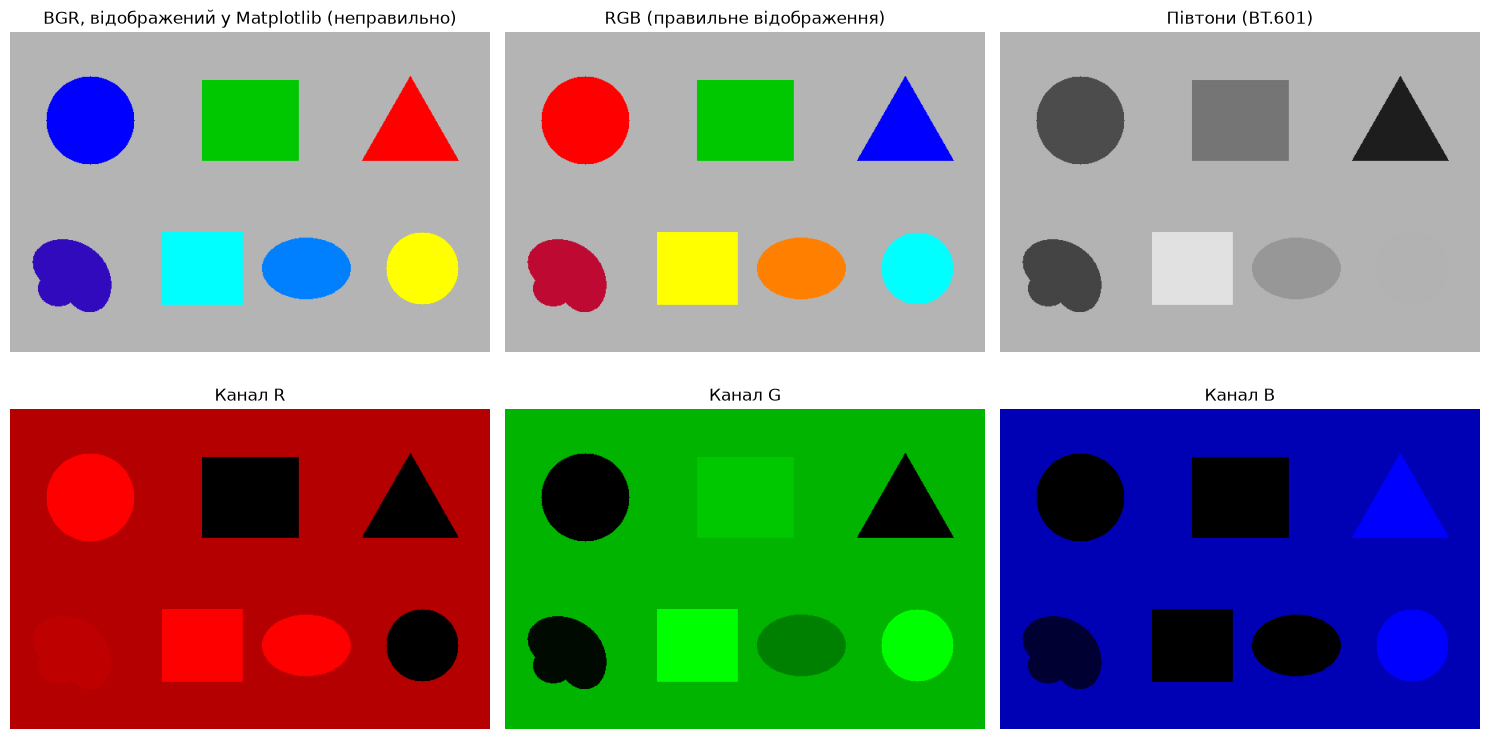

In [3]:
img_bgr = cv2.imread("data/test_image.png")            # OpenCV читає як BGR
img_pil = Image.open("data/test_image.png")            # Pillow читає як RGB
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

h, w, ch = img_bgr.shape
print("--- ТЕНЗОРНЕ ПОДАННЯ ЗОБРАЖЕННЯ ---")
print(f"Форма масиву (висота, ширина, канали): {img_bgr.shape}")
print(f"Кількість пікселів: {h * w}, значень у тензорі: {img_bgr.size}")
print(f"Тип даних: {img_bgr.dtype}, обсяг пам'яті: {img_bgr.nbytes / 1024:.1f} КБ")
print(f"Pillow: режим {img_pil.mode}, розмір (ширина, висота) {img_pil.size}")

# піксель, який у файлі має колір кола (100, 110): червоний
px_bgr = img_bgr[110, 100]
px_rgb = img_rgb[110, 100]
print(f"Піксель [110, 100]: у BGR = {px_bgr.tolist()}, у RGB = {px_rgb.tolist()}")

# розкладання на канали двома способами: cv2.split і зрізи NumPy
b_cv, g_cv, r_cv = cv2.split(img_bgr)
b_np, g_np, r_np = img_bgr[:, :, 0], img_bgr[:, :, 1], img_bgr[:, :, 2]
same_split = (np.array_equal(b_cv, b_np) and np.array_equal(g_cv, g_np)
              and np.array_equal(r_cv, r_np))
print(f"cv2.split і зрізи NumPy дають однакові канали: {same_split}")

# окремі канали у вигляді кольорових зображень (інші канали обнулено)
zeros = np.zeros_like(r_cv)
only_red = cv2.cvtColor(cv2.merge([zeros, zeros, r_cv]), cv2.COLOR_BGR2RGB)
only_green = cv2.cvtColor(cv2.merge([zeros, g_cv, zeros]), cv2.COLOR_BGR2RGB)
only_blue = cv2.cvtColor(cv2.merge([b_cv, zeros, zeros]), cv2.COLOR_BGR2RGB)

# перехід до півтонів за ваговими коефіцієнтами ITU-R BT.601
gray_manual = (0.2989 * r_np + 0.5870 * g_np + 0.1140 * b_np).astype(np.uint8)
gray_cv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
diff_gray = np.abs(gray_manual.astype(int) - gray_cv.astype(int)).max()
print(f"Півтони: max|власна формула - cv2.cvtColor| = {diff_gray} рівень")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].imshow(img_bgr)  # масив BGR без перетворення: червоний і синій міняються місцями
axes[0, 0].set_title("BGR, відображений у Matplotlib (неправильно)")
axes[0, 1].imshow(img_rgb)
axes[0, 1].set_title("RGB (правильне відображення)")
axes[0, 2].imshow(gray_manual, cmap='gray', vmin=0, vmax=255)
axes[0, 2].set_title("Півтони (BT.601)")
axes[1, 0].imshow(only_red)
axes[1, 0].set_title("Канал R")
axes[1, 1].imshow(only_green)
axes[1, 1].set_title("Канал G")
axes[1, 2].imshow(only_blue)
axes[1, 2].set_title("Канал B")
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/bgr_vs_rgb_channels.png", dpi=300)
plt.show()

**Результати тензорного аналізу:**

| Величина | Значення |
|---|---|
| Форма масиву (висота, ширина, канали) | (400, 600, 3) |
| Кількість пікселів / значень у тензорі | 240000 / 720000 |
| Тип даних / обсяг пам'яті | `uint8` / 703.1 КБ |
| Pillow: режим, розмір (ширина, висота) | RGB, (600, 400) |
| Піксель [110, 100] (центр червоного круга) | BGR = [0, 0, 255], RGB = [255, 0, 0] |
| `cv2.split` і зрізи NumPy | дають однакові канали |
| max різниця власної формули BT.601 та `cv2.cvtColor` | 1 рівень (різниця округлення) |

Той самий піксель у BGR та RGB має зворотний порядок компонент, тому при показі масиву BGR у Matplotlib без перетворення червоний круг стає синім, а синій трикутник — червоним (перший графік). Канал R підсвічує всі об'єкти, що містять червону складову (червоний, жовтий, оранжевий), а канал B — синій трикутник і блакитний круг. У півтонах блакитний круг майже зливається з тлом: його яскравість $0.587 \cdot 255 + 0.114 \cdot 255 \approx 179$ майже збігається з яскравістю тла (180), тобто перехід до півтонів втрачає різницю кольорів.

### Блок 3. Етап 2: перетворення в простори HSV та CIELab


--- ДІАПАЗОНИ КАНАЛІВ (8-бітне подання OpenCV) ---
HSV: H 0..173 (шкала 0..180), S 0..255, V 180..255
Lab: L 82..248 (0..255 замість 0..100), a 56..208, b 20..223 (нуль зсунуто на 128)
темно-червона пляма: H = 173, S = 242, V = 190
чисто червоний круг: H = 0, S = 255, V = 255


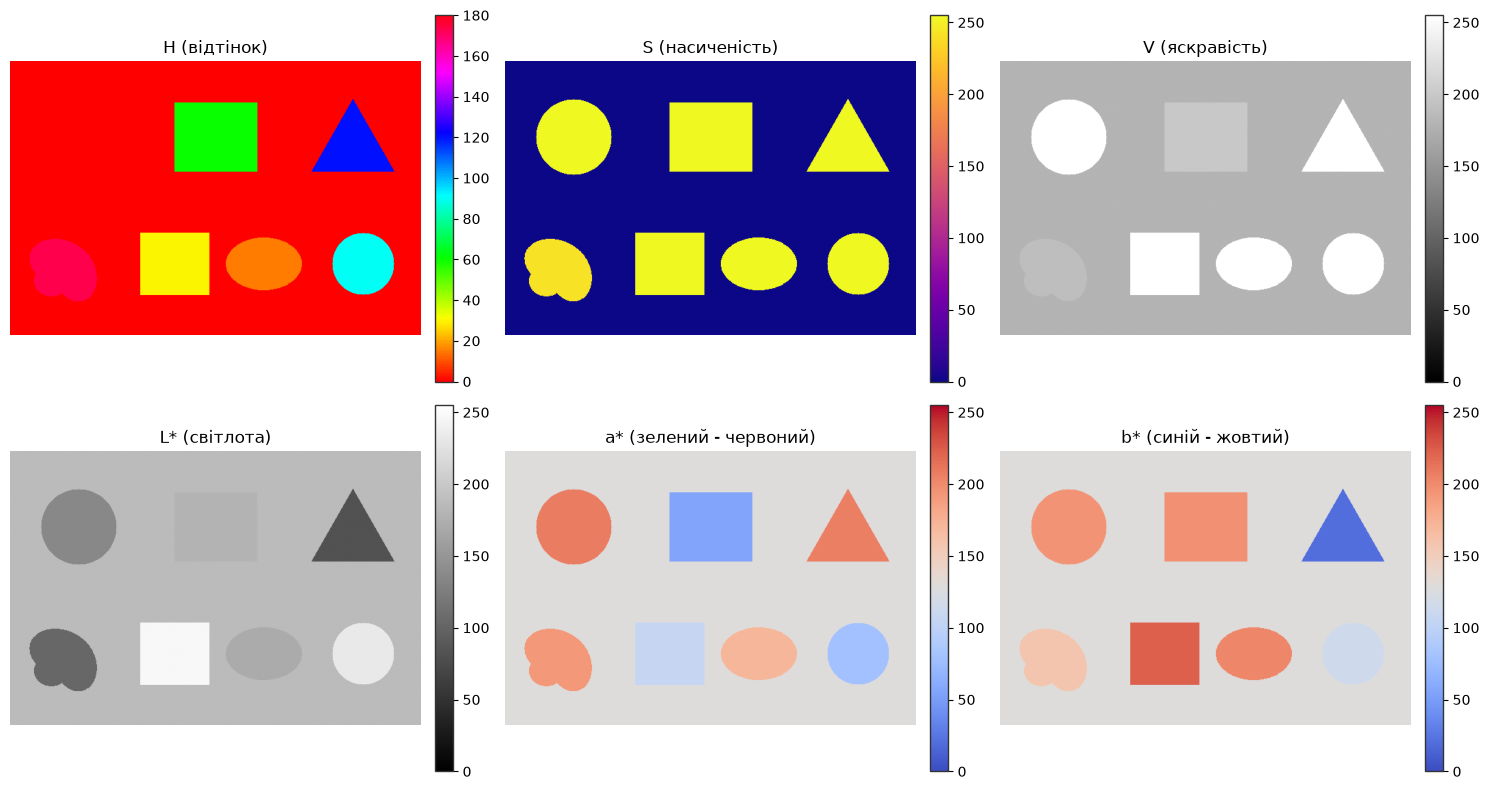

In [4]:
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2Lab)
H, S, V = cv2.split(img_hsv)
L_ch, a_ch, b_ch = cv2.split(img_lab)

print("\n--- ДІАПАЗОНИ КАНАЛІВ (8-бітне подання OpenCV) ---")
print(f"HSV: H {H.min()}..{H.max()} (шкала 0..180), S {S.min()}..{S.max()}, V {V.min()}..{V.max()}")
print(f"Lab: L {L_ch.min()}..{L_ch.max()} (0..255 замість 0..100), "
      f"a {a_ch.min()}..{a_ch.max()}, b {b_ch.min()}..{b_ch.max()} (нуль зсунуто на 128)")

# значення кольору плями та чистого червоного у просторі HSV
for name, (x, y) in {"темно-червона пляма": (75, 295), "чисто червоний круг": (100, 110)}.items():
    hh, ss, vv = img_hsv[y, x]
    print(f"{name}: H = {hh}, S = {ss}, V = {vv}")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
panels = [
    (H, "H (відтінок)", 'hsv', 0, 180),
    (S, "S (насиченість)", 'plasma', 0, 255),
    (V, "V (яскравість)", 'gray', 0, 255),
    (L_ch, "L* (світлота)", 'gray', 0, 255),
    (a_ch, "a* (зелений - червоний)", 'coolwarm', 0, 255),
    (b_ch, "b* (синій - жовтий)", 'coolwarm', 0, 255),
]
for ax, (data, title, cmap, vmin, vmax) in zip(axes.ravel(), panels):
    im = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
plt.tight_layout()
plt.savefig("figures/hsv_and_lab_spaces.png", dpi=300)
plt.show()

**Діапазони каналів у 8-бітному поданні OpenCV:**

| Простір | Канал | Діапазон на сцені | Повна шкала |
|---|---|---|---|
| HSV | H | 0 … 173 | 0 … 180 |
| HSV | S | 0 … 255 | 0 … 255 |
| HSV | V | 180 … 255 | 0 … 255 |
| Lab | L | 82 … 248 | 0 … 255 (замість 0 … 100) |
| Lab | a | 56 … 208 | 0 … 255, нуль на 128 |
| Lab | b | 20 … 223 | 0 … 255, нуль на 128 |

Значення для двох червоних об'єктів: темно-червона пляма має $H = 173$, $S = 242$, $V = 190$ (збігається з аналітичним розрахунком), а чисто червоний круг — $H = 0$, $S = 255$, $V = 255$. Тобто обидва об'єкти «червоні» для ока, але в просторі HSV їхні відтінки лежать на протилежних краях шкали ($0$ та $173$), що й вимагає двох діапазонів для повного червоного. Канал $V$ не опускається нижче 180, бо мінімальна яскравість сцени дорівнює яскравості тла. Сіре тло має $S = 0$, а за нульової насиченості відтінок не визначений (OpenCV ставить $H = 0$), тому на каналі $H$ тло та червоний круг мають однаковий колір: саме тому в порогу потрібна умова за насиченістю $S \ge 120$. На каналі $a^*$ (зелений–червоний) найбільші значення мають червоний круг і синій трикутник, найменші — зелений прямокутник і блакитний круг; на каналі $b^*$ (синій–жовтий) найвищі значення у жовтого та оранжевого об'єктів, найнижче — у синього трикутника.

### Блок 4. Етап 3: порогова сегментація в HSV (варіант 2: Red Part 2)


--- СЕГМЕНТАЦІЯ ЗА HSV ---
Діапазон варіанта 2: нижня межа [170, 120, 100], верхня межа [180, 255, 255]
Маска                                 Площа, пікс.   Частка кадру, %
Варіант 2 (H 170..180)                        6928              2.89
Червоний, частина 1 (H 0..10)                 9477              3.95
Червоний повний (частини 1 + 2)              16405              6.84
Еталонна площа плями: 6928 пікс.; перетин з маскою: 6928 пікс.; IoU = 1.0000
Червоний круг у маску варіанта 2 потрапляє: False (його відтінок H = 0)
Зведення: зображення 400x600, 240000 пікс., uint8, 703.1 КБ


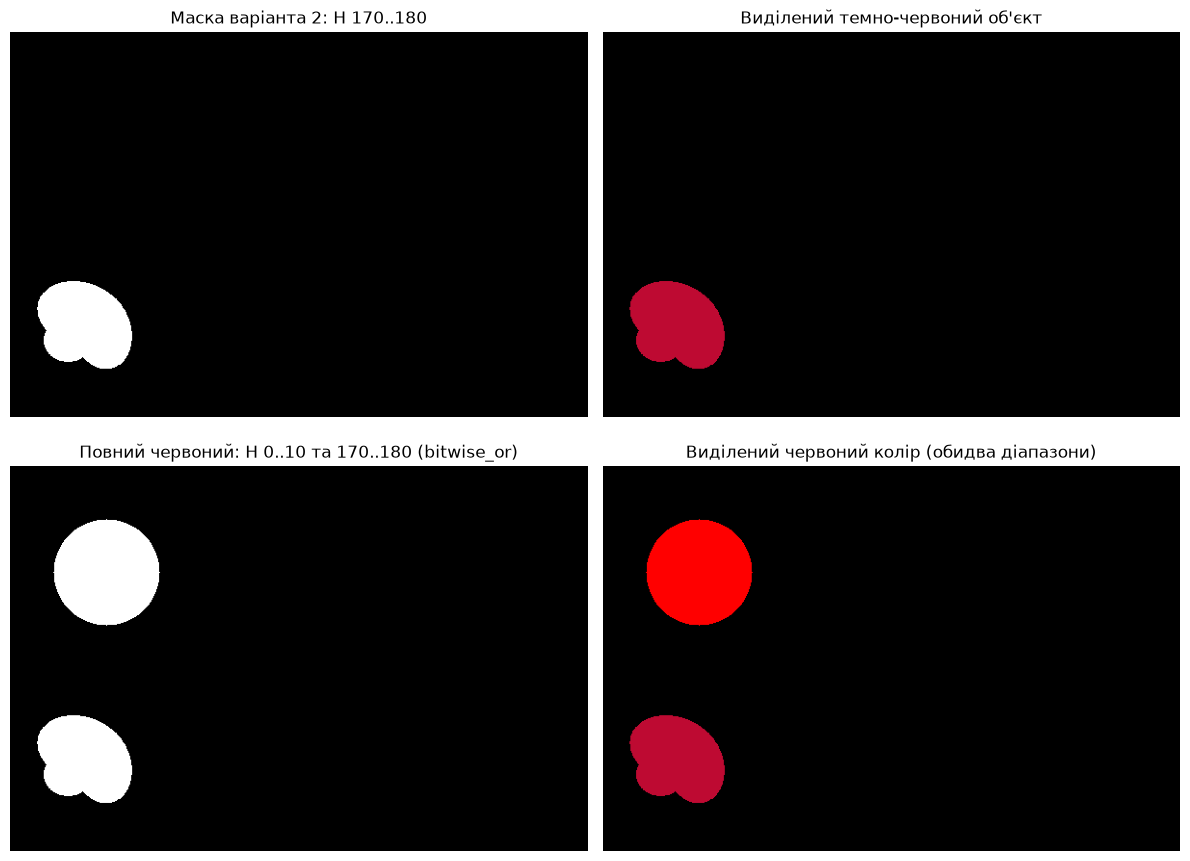


Моделювання завершено. Графіки збережено в 'figures/'.


In [5]:
# діапазон варіанта 2 у шкалі OpenCV: H 0..180, S і V 0..255
lower_v2 = np.array([170, 120, 100])
upper_v2 = np.array([180, 255, 255])
mask_v2 = cv2.inRange(img_hsv, lower_v2, upper_v2)
segmented_v2 = cv2.bitwise_and(img_bgr, img_bgr, mask=mask_v2)

# повний червоний колір: відтінок переходить через 0, тому потрібні два діапазони
mask_red_low = cv2.inRange(img_hsv, np.array([0, 120, 100]), np.array([10, 255, 255]))
mask_red_full = cv2.bitwise_or(mask_red_low, mask_v2)
segmented_full = cv2.bitwise_and(img_bgr, img_bgr, mask=mask_red_full)

total_px = h * w
area_v2 = cv2.countNonZero(mask_v2)
area_low = cv2.countNonZero(mask_red_low)
area_full = cv2.countNonZero(mask_red_full)

# перевірка за еталонною маскою плями
inter = np.logical_and(mask_v2 > 0, gt_blotch > 0).sum()
union = np.logical_or(mask_v2 > 0, gt_blotch > 0).sum()
gt_area = cv2.countNonZero(gt_blotch)

print("\n--- СЕГМЕНТАЦІЯ ЗА HSV ---")
print(f"Діапазон варіанта 2: нижня межа {lower_v2.tolist()}, верхня межа {upper_v2.tolist()}")
print(f"{'Маска':<36}{'Площа, пікс.':>14}{'Частка кадру, %':>18}")
print(f"{'Варіант 2 (H 170..180)':<36}{area_v2:>14}{100 * area_v2 / total_px:>18.2f}")
print(f"{'Червоний, частина 1 (H 0..10)':<36}{area_low:>14}{100 * area_low / total_px:>18.2f}")
print(f"{'Червоний повний (частини 1 + 2)':<36}{area_full:>14}{100 * area_full / total_px:>18.2f}")
print(f"Еталонна площа плями: {gt_area} пікс.; перетин з маскою: {inter} пікс.; IoU = {inter / union:.4f}")
print(f"Червоний круг у маску варіанта 2 потрапляє: "
      f"{bool(mask_v2[110, 100])} (його відтінок H = {img_hsv[110, 100, 0]})")
print(f"Зведення: зображення {h}x{w}, {total_px} пікс., {img_bgr.dtype}, "
      f"{img_bgr.nbytes / 1024:.1f} КБ")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].imshow(mask_v2, cmap='gray')
axes[0, 0].set_title("Маска варіанта 2: H 170..180")
axes[0, 1].imshow(cv2.cvtColor(segmented_v2, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title("Виділений темно-червоний об'єкт")
axes[1, 0].imshow(mask_red_full, cmap='gray')
axes[1, 0].set_title("Повний червоний: H 0..10 та 170..180 (bitwise_or)")
axes[1, 1].imshow(cv2.cvtColor(segmented_full, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title("Виділений червоний колір (обидва діапазони)")
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/hsv_color_segmentation.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Результати сегментації:**

| Маска | Площа, пікс. | Частка кадру, % |
|---|---|---|
| Варіант 2, $H \in [170, 180]$ | 6928 | 2.89 |
| Червоний, частина 1, $H \in [0, 10]$ | 9477 | 3.95 |
| Червоний повний (частини 1 + 2) | 16405 | 6.84 |

Зведення: зображення $400 \times 600$, 240000 пікселів, `uint8`, 703.1 КБ. Площа плями за маскою (6928 пікс.) збігається з еталонною площею, отриманою від самої фігури, перетин 6928 пікс., $IoU = 1.0000$ (на синтетичній сцені без шуму межі кольорів різкі). Чисто червоний круг у маску варіанта 2 не потрапляє (його $H = 0$), тому маска виділяє лише темно-червону пляму; об'єднання двох масок за `cv2.bitwise_or` дає і круг, і пляму (6.84 % кадру), що наочно показує розрив відтінку червоного на межі шкали.

## 5. Висновки

1. Зображення в Python — це тензор `uint8` форми (400, 600, 3), що займає 703.1 КБ. OpenCV читає канали в порядку BGR, а Matplotlib і Pillow працюють з RGB; без `cv2.cvtColor(..., COLOR_BGR2RGB)` червоний і синій канали міняються місцями, що видно на прикладі червоного круга та синього трикутника.

2. `cv2.split` і зрізи NumPy дають однакові канали. Власна формула півтонів BT.601 відрізняється від `cv2.cvtColor` не більше ніж на 1 рівень; блакитний об'єкт у півтонах майже зливається з тлом, тому при переході до півтонів частина інформації про колір втрачається.

3. У просторі HSV колір задається відтінком, що відокремлює його від яскравості та насиченості, тому поріг за $H$ не залежить від освітленості так, як пороги за $R$, $G$, $B$. Для варіанта 2 (темно-червоний, $H \in [170, 180]$, $S \ge 120$, $V \ge 100$) маска виділила пляму площею 6928 пікс. (2.89 % кадру), $IoU = 1.0000$ відносно еталона, а чисто червоний круг ($H = 0$) у неї не потрапив.

4. Через перехід відтінку червоного через $0^\circ / 360^\circ$ повний червоний колір потребує двох діапазонів ($0 \ldots 10$ та $170 \ldots 180$) і `cv2.bitwise_or`: разом вони дали 16405 пікс. (6.84 %). Діапазон варіанта 2 охоплює «хвіст» червоного поряд з пурпуровим, що відповідає вузькому застосуванню, наприклад виділенню темно-червоних областей (крововиливів) на медичних знімках.

5. У 8-бітному поданні OpenCV $H$ має діапазон $0 \ldots 180$, а $L, a, b$ — $0 \ldots 255$ зі зсувом нуля $a, b$ на 128; ці масштаби слід враховувати при виборі порогів. Результати отримано на синтетичній сцені без шуму; на реальних знімках пороги довелося б підбирати з урахуванням шуму та освітлення.

## Відповідь на контрольні питання

**1. Як влаштоване представлення кольорового цифрового зображення у вигляді тривимірного тензора в бібліотеці NumPy, і що визначає кожен із трьох індексів $I[y, x, c]$?**

* **Структура тензора в NumPy:** Кольорове цифрове зображення зберігається у вигляді тривимірного масиву (`numpy.ndarray`) розмірністю $(H, W, C)$ (висота $\times$ ширина $\times$ кількість колірних каналів), зазвичай із типом даних `uint8` (беззнакові цілі числа в діапазоні $[0, 255]$) та порядком розміщення елементів у пам'яті за рядками (C-order / row-major).
* **Значення кожного з трьох індексів $I[y, x, c]$:**
* **$y \in [0, H - 1]$** — вертикальна координата (індекс рядка), відлічується зверху вниз від верхньої межі зображення;
* **$x \in [0, W - 1]$** — горизонтальна координата (індекс стовпця), відлічується зліва направо від лівої межі зображення;
* **$c \in [0, C - 1]$** — індекс колірного каналу (для триканального зображення $C = 3$, де $c = 0, 1, 2$ відповідають компонентам BGR або RGB; за наявності альфа-каналу прозорості $C = 4$).



---

**2. Чому при читанні файлу зображення засобами OpenCV використовується порядок каналів $\text{BGR}$, і які спотворення виникають при спробі його безпосереднього відображення бібліотекою Matplotlib?**

* **Причина використання порядку $\text{BGR}$ в OpenCV:** Це історична особливість, закладена під час створення бібліотеки наприкінці 1990-х — на початку 2000-х років. У той період стандарт BGR широко застосовувався виробниками камер, графічних адаптерів та в операційній системі Windows (зокрема у форматі BMP та 32-бітному представленні кольору `COLORREF`, де через порядок байтів little-endian наймолодшим у пам'яті розташовувався синій канал).
* **Спотворення при відображенні в Matplotlib:** Функція `matplotlib.pyplot.imshow()` інтерпретує триканальні масиви виключно у стандартному порядку **RGB**. Під час прямого виведення BGR-масиву червоний ($R$) та синій ($B$) канали міняються місцями (інвертуються), тоді як зелений ($G$) залишається незмінним. Внаслідок цього сині об'єкти на зображенні стають помаранчево-червоними, а червоні та тілесні відтінки — синьо-блакитними.

---

**3. За якою математичною залежністю здійснюється перетворення кольорового $\text{RGB}$-зображення у монохромне напівтонове (Grayscale) за стандартом $\text{ITU-R BT.601}$, і чому вага зеленого каналу є найбільшою?**

* **Математична залежність (стандарт ITU-R BT.601):** Яскравість напівтонового пікселя $Y$ обчислюється як зважена сума інтенсивностей червоного ($R$), зеленого ($G$) та синього ($B$) каналів:

$$Y = 0.299 \cdot R + 0.587 \cdot G + 0.114 \cdot B$$



(Сума коефіцієнтів дорівнює $1$, що зберігає вихідний діапазон значень яскравості $[0, 255]$).
* **Чому вага зеленого каналу є найбільшою ($0.587$):** Це зумовлено фізіологією людського зору (кривою спектральної чутливості денного зору). Фоторецептори сітківки ока людини (зокрема L- та M-колбочки) мають максимальну чутливість у жовто-зеленій області спектра (поблизу довжини хвилі $555\text{ нм}$). Тому за однакової фізичної енергії випромінювання зелений колір сприймається людським оком як значно яскравіший за червоний і тим більше за синій.

---

**4. У чому полягає геометрична структура та фізичний зміст компонентів циліндричного колірного простору $\text{HSV}$ (Hue, Saturation, Value)?**

* **Геометрична структура:** Простір HSV описується циліндричною системою координат (часто також візуалізується у вигляді перевернутого конуса або гексаконуса), де колір визначається кутом повороту навколо вертикальної осі, радіальною відстанню від осі та висотою вздовж осі.
* **Фізичний зміст компонентів:**
* **$H$ (Hue — колірний тон):** Кутова координата навколо центральної осі ($0^\circ \dots 360^\circ$), що визначає власне спектральний відтінок кольору (наприклад, $0^\circ$ — червоний, $60^\circ$ — жовтий, $120^\circ$ — зелений, $180^\circ$ — блакитний, $240^\circ$ — синій, $300^\circ$ — пурпуровий).
* **$S$ (Saturation — насиченість):** Радіальна відстань від центральної осі ($0\% \dots 100\%$), що характеризує чистоту кольору (ступінь його нерозбавленості білим). На центральній осі ($S = 0$) знаходяться ахроматичні відтінки сірого, а на зовнішній бічній поверхні циліндра ($S = 100\%$) — максимально насичені чисті кольори.
* **$V$ (Value — яскравість / світлота):** Вертикальна координата вздовж осі ($0\% \dots 100\%$), що відображає загальну інтенсивність випромінювання. Нижня площина ($V = 0$) відповідає абсолютно чорному кольору незалежно від значень $H$ і $S$, а верхня межа ($V = 100\%$) — максимальній яскравості обраного відтінку (при $S = 0, V = 100\%$ отримуємо чисто білий колір).



---

**5. Чому значення колірного тону $H$ в 8-бітній реалізації OpenCV обмежене діапазоном $[0, 180]$, і як правильно виконати сегментацію об'єктів червоного кольору, сектор яких розривається на межі $0^\circ$ та $360^\circ$?**

* **Причина обмеження діапазону $[0, 180]$ в OpenCV:** У 8-бітному беззнаковому форматі `uint8` один піксель каналу може зберігати цілі числа лише від $0$ до $255$. Оскільки повний кут колірного кола ($360^\circ$) не вміщується в один байт без втрати цілочисельного представлення, в OpenCV значення кута в градусах ділять навпіл ($H_{\text{OpenCV}} = H_{\text{deg}} / 2$), переводячи інтервал $[0^\circ, 360^\circ)$ у діапазон $[0, 180)$ (або $[0, 180]$).
* **Правильна сегментація об'єктів червоного кольору:** Через циклічність колірного кола сектор червоного кольору розривається на два окремі інтервали поблизу межі $0^\circ / 360^\circ$: нижній ($H \in [0, 10]$) та верхній ($H \in [170, 180]$ у шкалі OpenCV). Для виділення всіх червоних об'єктів:
1. Формують **дві окремі бінарні маски** функцією `cv2.inRange()` для обох інтервалів тону $H$ (одночасно обмежуючи знизу $S$ та $V$, щоб відсіяти білі, сірі та чорні ділянки).
2. Об'єднують ці дві маски за допомогою побітового логічного «АБО» (`cv2.bitwise_or(mask1, mask2)`).



---

**6. Які переваги надає рівноконтрастний колірний простір $\text{CIELab}$ ($L^*a^*b^*$) порівняно з простором $\text{RGB}$ при оцінці колірних відмінностей ($\Delta E$)?**

* **Перцептивна рівномірність (рівноконтрастність):** У просторі RGB однакова геометрична відстань між парами точок у різних областях колірного куба сприймається людським оком як зовсім різна за величиною зміна кольору. Простір $\text{CIELab}$ спроєктовано так, щоб однакові евклідові відстані між точками відповідали однаковим суб'єктивним колірним відмінностям, які фіксує людський зір.
* **Коректність евклідової метрики $\Delta E$:** Завдяки рівноконтрастності відмінність між двома кольорами $(L_1^*, a_1^*, b_1^*)$ і $(L_2^*, a_2^*, b_2^*)$ обчислюється безпосередньо як звичайна евклідова відстань:

$$\Delta E_{ab}^* = \sqrt{(L_2^* - L_1^*)^2 + (a_2^* - a_1^*)^2 + (b_2^* - b_1^*)^2}$$



що має пряму фізичну інтерпретацію (наприклад, $\Delta E < 1$ практично не розрізняється людським оком).
* **Відокремлення яскравості від хроматичності та апаратна незалежність:** Компонента $L^*$ ізолює світлоту (яскравість) від колірних координат $a^*$ (вісь «зелений — червоний») та $b^*$ (вісь «синій — жовтий»), що дозволяє порівнювати відтінки незалежно від перепадів освітленості, а сам простір не залежить від характеристик конкретного дисплея чи камери.

---

**7. Яким чином побітові логічні операції (`cv2.bitwise_and`) взаємодіють із бінарними масками для просторової фільтрації та вилучення цільових сегментів зображення?**

Функція `cv2.bitwise_and(src1, src2, mask=mask)` виконує побітове логічне множення («І») між відповідними бітами пікселів вхідних зображень лише в тих координатах $(y, x)$, де значення пікселя одноканальної бінарної маски відмінне від нуля (`mask[y, x] != 0`, зазвичай `255` або `0b11111111`):

* **Збереження цільового сегмента (переднього плану):** У точках, де маска дорівнює `255` (`1` у всіх бітах), побітове «І» зображення самого з собою залишає значення всіх бітів кожного колірного каналу незмінними ($I \land \text{0xFF} = I$), повністю зберігаючи оригінальний колір та текстуру об'єкта.
* **Пригнічення фону:** У точках, де маска дорівнює `0` (`0b00000000`), результат операції примусово обнуляється ($I \land \text{0x00} = 0$), зафарбовуючи всі фонові пікселі чорним кольором.

Таким чином, бінарна маска працює як просторовий «трафарет», дозволяючи ізолювати виділену область інтересу (ROI) для подальшого вимірювання її параметрів або комбінування з іншим фоном.